In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import joblib
import pandas as pd
import numpy as np

from src.data.loader import load_parquet
from src.models.baseline import FEATURE_COLUMNS, split_X_y
from src.explainability.shap_wrapper import ShapExplainer

# Load trained model + feature-engineered splits
rf_pipeline = joblib.load("../models/rf_pipeline.joblib")
val_df = load_parquet("../data/processed/val_fe.parquet")
X_val, y_val = split_X_y(val_df)

print(f"Loaded RF pipeline and {len(X_val):,} validation rows.")
print(f"Features in use: {len(FEATURE_COLUMNS)}")

Loaded RF pipeline and 42,721 validation rows.
Features in use: 35


In [2]:
from time import time

t0 = time()
explainer = ShapExplainer(rf_pipeline, FEATURE_COLUMNS)
print(f"TreeExplainer initialized in {time() - t0:.1f} seconds.")

TreeExplainer initialized in 0.0 seconds.


In [3]:
# Find the single highest-risk transaction in validation
val_probs = rf_pipeline.predict_proba(X_val)[:, 1]
top_idx = int(np.argmax(val_probs))

x_row = X_val.iloc[top_idx]
y_true = y_val.iloc[top_idx]

exp = explainer.explain_one(x_row, top_k=8)

print(f"Transaction index: {top_idx}")
print(f"Actual class:      {'Fraud' if y_true == 1 else 'Legitimate'}")
print(f"Base value:        {exp.base_value:.4f}  (model's starting prediction)")
print(f"Model prediction:  {exp.prediction:.4f}  (final fraud probability)")
print(f"\nTop 8 contributing features:")
print(exp.top_contributors.to_string(index=False))

Transaction index: 24253
Actual class:      Fraud
Base value:        0.4985  (model's starting prediction)
Model prediction:  0.9750  (final fraud probability)

Top 8 contributing features:
feature     value     shap
    V14 -8.893726 0.113709
    V17 -4.368986 0.075296
    V10 -4.400930 0.073199
    V12 -5.737815 0.067567
     V4  7.232058 0.045441
     V3 -5.463811 0.043014
    V11  4.213213 0.040419
    V16 -3.281784 0.040266


In [4]:
# Sample 5000 random rows (full computation on 42k would take minutes)
sample_X = X_val.sample(n=5000, random_state=42)
print(f"Computing global SHAP importance on {len(sample_X):,} sampled rows...")

t0 = time()
global_imp = explainer.global_importance(sample_X)
print(f"Done in {time() - t0:.1f} seconds.\n")

print("Top 15 features by mean(|SHAP|):")
print(global_imp.head(15).to_string(index=False))

Computing global SHAP importance on 5,000 sampled rows...
Done in 59.4 seconds.

Top 15 features by mean(|SHAP|):
feature  mean_abs_shap
    V12       0.070094
    V14       0.055434
     V4       0.054753
    V11       0.052519
    V10       0.041795
    V17       0.036162
     V3       0.026874
    V16       0.023651
     V1       0.018960
     V7       0.015836
     V2       0.012013
    V18       0.011915
     V9       0.007971
     V5       0.006300
    V21       0.005520


In [5]:
# Find a borderline transaction: probability close to the production threshold
PRODUCTION_THRESHOLD = 0.0358

# Among transactions where model and reality differ most, find a Medium-tier one
val_probs = rf_pipeline.predict_proba(X_val)[:, 1]

# Pick a transaction in the Medium tier that was actually fraud (interesting case)
medium_mask = (val_probs >= PRODUCTION_THRESHOLD) & (val_probs < 0.0755)
medium_fraud_mask = medium_mask & (y_val.values == 1)
medium_fraud_indices = np.where(medium_fraud_mask)[0]

if len(medium_fraud_indices) > 0:
    # Pick the one with the lowest confidence (most borderline)
    borderline_idx = int(medium_fraud_indices[np.argmin(val_probs[medium_fraud_indices])])
else:
    # Fallback: just pick a Medium-tier case regardless of label
    medium_indices = np.where(medium_mask)[0]
    borderline_idx = int(medium_indices[0])

x_row = X_val.iloc[borderline_idx]
y_true = y_val.iloc[borderline_idx]
prob = val_probs[borderline_idx]

exp = explainer.explain_one(x_row, top_k=8)

print(f"Transaction index:  {borderline_idx}")
print(f"Actual class:       {'Fraud' if y_true == 1 else 'Legitimate'}")
print(f"Model probability:  {prob:.4f}  (Medium tier)")
print(f"Base value:         {exp.base_value:.4f}")
print(f"Model prediction:   {exp.prediction:.4f}")
print(f"\nTop 8 contributing features:")
print(exp.top_contributors.to_string(index=False))

Transaction index:  39102
Actual class:       Fraud
Model probability:  0.0400  (Medium tier)
Base value:         0.4985
Model prediction:   0.0400

Top 8 contributing features:
feature     value      shap
    V12 -0.022561 -0.090819
    V10  0.398155 -0.074447
    V16  2.464450 -0.053806
    V14 -2.969201  0.052607
     V4  3.893556  0.050939
     V1  1.833191 -0.043138
    V17  0.671241 -0.035746
    V18  1.921021 -0.032193


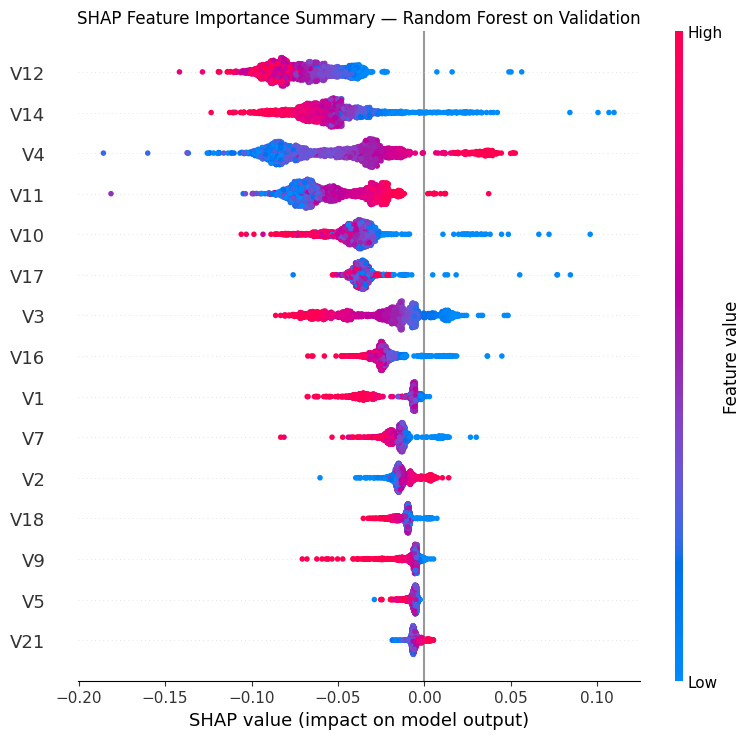

In [6]:
import matplotlib.pyplot as plt
import shap

# Compute SHAP values on a sample for the plot
sample_X = X_val.sample(n=2000, random_state=42)
sample_shap = explainer.explain_many(sample_X)

# Beeswarm plot — the SHAP summary
shap.summary_plot(
    sample_shap,
    sample_X,
    feature_names=X_val.columns.tolist(),
    max_display=15,
    show=False,
)
plt.title("SHAP Feature Importance Summary — Random Forest on Validation")
plt.tight_layout()
plt.show()